# Reward-proximity sweep: a dose-response test of the metapolicy-GPI gap mechanism

`06_maze_ablation.ipynb` refuted the "walls create the gap" hypothesis (identical
results with and without internal walls). Looking at *why* it failed pointed to the
real mechanism: `Psi_j(s,a) = phi(s,a) + gamma*Psi_j(s', pi_j(s'))` doesn't know or
care which weight `pi_j` was trained for -- if a state on `pi_j`'s own optimal path
happens to be one step from a *different* reward, `pi_j`'s own SF table already
registers real value in that other dimension, purely as a side effect of `phi`'s
reward-identity-agnostic bookkeeping. GPI (full action set, `argmax_a max_j
Psi_j(s,a).w`) can exploit that immediately, even with a single policy (`k=1`).
Metapolicy, restricted to `pi_j`'s own literal greedy action, cannot. A quick
30-second check confirmed the direction: `diff=0.0000` with rewards far apart,
`diff=0.0089` with rewards 2 cells apart.

This notebook turns that one-off check into an actual result: **sweep the distance `d`
between two rewards as a controlled parameter**, holding everything else fixed (grid,
start, reward0's position, gamma, test weights), and measure the gap as a function of
`d`. Predicted shape: gap should shrink monotonically (or near-monotonically) as `d`
grows, and vanish once `d` is large enough that no state on `pi(e_0)`'s own path is
ever within one step of reward1.

A second question this setting can answer for free: does pool-feedback, using only
**one** real exact solve (`k=1`) plus cheap composition from a separate sample of build
weights, recover the quality of the full 2-exact-solve GPI basis (`k=2`)? If so, that's
a much stronger efficiency claim than anything measured so far -- full-basis GPI
quality from a fraction of the exact-solve cost.

## 1. A parameterized two-reward domain: distance `d` is the only thing that varies

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(suppress=True, precision=4)

GAMMA = 0.99
SEED = 0
N_ACTIONS = 4  # up, down, left, right
GRID = 21      # rows/cols 0..20, interior 1..19
DIR = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}
FEAT_DIM = 2

START = (10, 1)
REWARD0 = (10, 19)   # straight path along row 10 from START: length 18, gamma<1 makes
                     # this path uniquely shortest (any detour costs 2 extra steps),
                     # so pi(e_0)'s optimal trajectory hugs row 10 exactly.
PATH_MIDPOINT_COL = 10  # reward1 sits directly "above" this point on pi(e_0)'s path


def build_domain(d):
    """reward1 = (10-d, PATH_MIDPOINT_COL) -- its Manhattan distance to the NEAREST
    point on pi(e_0)'s own straight-line path, (10, PATH_MIDPOINT_COL), is exactly d."""
    reward1 = (10 - d, PATH_MIDPOINT_COL)
    rewards = {0: REWARD0, 1: reward1}
    occ = {(r, c) for r in range(GRID) for c in range(GRID) if r == 0 or r == GRID - 1 or c == 0 or c == GRID - 1}
    states = [(r, c) for r in range(GRID) for c in range(GRID) if (r, c) not in occ]
    state_idx = {s: i for i, s in enumerate(states)}
    reward_idx = {pos: i for i, pos in rewards.items()}
    is_terminal = {s: s in reward_idx for s in states}
    nonterminal = [s for s in states if not is_terminal[s]]
    return dict(occupied=occ, states=states, state_idx=state_idx, is_terminal=is_terminal,
                nonterminal=nonterminal, reward_idx=reward_idx, rewards=rewards, d=d)


def step_deterministic(dom, s, a):
    dr, dc = DIR[a]
    ns = (s[0] + dr, s[1] + dc)
    if ns in dom["occupied"] or ns not in dom["state_idx"]:
        ns = s
    terminal = ns in dom["reward_idx"]
    phi = np.zeros(FEAT_DIM)
    if terminal:
        phi[dom["reward_idx"][ns]] = 1.0
    return ns, phi, terminal


D_VALUES = [1, 2, 3, 4, 5, 6, 7, 8, 9]
for d in [1, 5, 9]:
    dom = build_domain(d)
    print(f"d={d}: reward1={dom['rewards'][1]}, {len(dom['states'])} states")

d=1: reward1=(9, 10), 361 states
d=5: reward1=(5, 10), 361 states
d=9: reward1=(1, 10), 361 states


## 2. Exact solvers (same construction as `06_maze_ablation.ipynb`, parameterized by `dom`)

In [2]:
class SFTable:
    def __init__(self, num_actions, feat_dim, default_vec):
        self.default_vec = default_vec
        self.table = {}

    def __getitem__(self, state):
        if state not in self.table:
            self.table[state] = self.default_vec.copy()
        return self.table[state]


def policy_iteration(dom, w, gamma=GAMMA):
    states, state_idx, nonterminal = dom["states"], dom["state_idx"], dom["nonterminal"]
    n = len(states)
    policy = {s: 0 for s in nonterminal}
    while True:
        A, b = np.eye(n), np.zeros(n)
        for s in nonterminal:
            i = state_idx[s]
            ns, phi, term = step_deterministic(dom, s, policy[s])
            b[i] = phi @ w
            if not term:
                A[i, state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[state_idx[s]] for s in states}
        stable = True
        for s in nonterminal:
            qs = []
            for a in range(N_ACTIONS):
                ns, phi, term = step_deterministic(dom, s, a)
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_a = int(np.argmax(qs))
            stable &= best_a == policy[s]
            policy[s] = best_a
        if stable:
            return policy, V


def solve_task_exact(dom, w, gamma=GAMMA):
    states, state_idx, nonterminal = dom["states"], dom["state_idx"], dom["nonterminal"]
    n = len(states)
    policy, _ = policy_iteration(dom, w, gamma)
    A, b = np.eye(n), np.zeros((n, FEAT_DIM))
    for s in nonterminal:
        i = state_idx[s]
        ns, phi, term = step_deterministic(dom, s, policy[s])
        b[i] = phi
        if not term:
            A[i, state_idx[ns]] -= gamma
    V_vec = np.linalg.solve(A, b)
    V_vec = {s: V_vec[state_idx[s]] for s in states}

    psi = SFTable(N_ACTIONS, FEAT_DIM, np.zeros((N_ACTIONS, FEAT_DIM)))
    for s in nonterminal:
        table = np.zeros((N_ACTIONS, FEAT_DIM))
        for a in range(N_ACTIONS):
            ns, phi, term = step_deterministic(dom, s, a)
            table[a] = phi if term else phi + gamma * V_vec[ns]
        psi.table[s] = table
    return psi


def evaluate_fixed_policy_scalar(dom, action_fn, w, gamma=GAMMA):
    states, state_idx, nonterminal = dom["states"], dom["state_idx"], dom["nonterminal"]
    n = len(states)
    A, b = np.eye(n), np.zeros(n)
    for s in nonterminal:
        i = state_idx[s]
        ns, phi, term = step_deterministic(dom, s, action_fn(s))
        b[i] = phi @ w
        if not term:
            A[i, state_idx[ns]] -= gamma
    v = np.linalg.solve(A, b)
    return {s: v[state_idx[s]] for s in states}


def own_greedy_actions(dom, sf_table, w):
    return {s: int(np.argmax(sf_table[s] @ w)) for s in dom["nonterminal"]}


def meta_policy_iteration_warm(dom, w, Pi_base, W_base, gamma=GAMMA, gpi_init=True, max_sweeps=500):
    states, state_idx, nonterminal = dom["states"], dom["state_idx"], dom["nonterminal"]
    n = len(states)
    own_actions = [own_greedy_actions(dom, sft, w_j) for sft, w_j in zip(Pi_base, W_base)]
    if gpi_init:
        meta_policy = {}
        for s in nonterminal:
            vals = [Pi_base[j][s][own_actions[j][s]] @ w for j in range(len(Pi_base))]
            meta_policy[s] = int(np.argmax(vals))
    else:
        meta_policy = {s: 0 for s in nonterminal}

    n_sweeps = 0
    while True:
        n_sweeps += 1
        A, b = np.eye(n), np.zeros(n)
        for s in nonterminal:
            i = state_idx[s]
            ns, phi, term = step_deterministic(dom, s, own_actions[meta_policy[s]][s])
            b[i] = phi @ w
            if not term:
                A[i, state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[state_idx[s]] for s in states}
        stable = True
        for s in nonterminal:
            qs = []
            for j in range(len(Pi_base)):
                ns, phi, term = step_deterministic(dom, s, own_actions[j][s])
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_j = int(np.argmax(qs))
            stable &= best_j == meta_policy[s]
            meta_policy[s] = best_j
        if stable or n_sweeps >= max_sweeps:
            return meta_policy, V, own_actions, n_sweeps


def meta_policy_sf(dom, meta_policy, own_actions, gamma=GAMMA):
    states, state_idx, nonterminal = dom["states"], dom["state_idx"], dom["nonterminal"]
    n = len(states)
    A, b = np.eye(n), np.zeros((n, FEAT_DIM))
    for s in nonterminal:
        i = state_idx[s]
        ns, phi, term = step_deterministic(dom, s, own_actions[meta_policy[s]][s])
        b[i] = phi
        if not term:
            A[i, state_idx[ns]] -= gamma
    Psi_arr = np.linalg.solve(A, b)
    return {s: Psi_arr[state_idx[s]] for s in states}


def meta_policy_sf_full(dom, meta_policy, own_actions, gamma=GAMMA, Psi_own=None):
    if Psi_own is None:
        Psi_own = meta_policy_sf(dom, meta_policy, own_actions, gamma)
    table = SFTable(N_ACTIONS, FEAT_DIM, np.zeros((N_ACTIONS, FEAT_DIM)))
    for s in dom["nonterminal"]:
        full = np.zeros((N_ACTIONS, FEAT_DIM))
        for a in range(N_ACTIONS):
            ns, phi, term = step_deterministic(dom, s, a)
            full[a] = phi if term else phi + gamma * Psi_own[ns]
        table.table[s] = full
    return table


def bellman_gap(dom, w, V_meta, gamma=GAMMA):
    gaps = {}
    for s in dom["nonterminal"]:
        qs = []
        for a in range(N_ACTIONS):
            ns, phi, term = step_deterministic(dom, s, a)
            qs.append(phi @ w + (0.0 if term else gamma * V_meta[ns]))
        gaps[s] = max(qs) - V_meta[s]
    return gaps


def gpi_full_actions(dom, Pi, w):
    actions = {}
    for s in dom["nonterminal"]:
        vals = [max(psi[s][a] @ w for psi in Pi) for a in range(N_ACTIONS)]
        actions[s] = int(np.argmax(vals))
    return actions


def gpi_value(dom, Pi_snapshot, w, gamma=GAMMA):
    actions = gpi_full_actions(dom, Pi_snapshot, w)
    return evaluate_fixed_policy_scalar(dom, lambda s: actions[s], w, gamma)


def metapolicy_value(dom, Pi_base, W_base, w, gamma=GAMMA):
    _, V, _, _ = meta_policy_iteration_warm(dom, w, Pi_base, W_base, gamma)
    return V


def grow_pool_with_metapolicy_feedback(dom, Pi_base, W_base, build_weights, gamma=GAMMA, cert_tol=1e-6):
    Pi_base, W_base = list(Pi_base), list(W_base)
    n_added = 0
    for w in build_weights:
        meta_policy, V, own_actions, _ = meta_policy_iteration_warm(dom, w, Pi_base, W_base, gamma)
        worst_gap = max(bellman_gap(dom, w, V, gamma).values())
        if worst_gap <= cert_tol:
            Psi_own = meta_policy_sf(dom, meta_policy, own_actions, gamma)
            Pi_base.append(meta_policy_sf_full(dom, meta_policy, own_actions, gamma, Psi_own=Psi_own))
            W_base.append(w)
            n_added += 1
    return Pi_base, W_base, n_added

## 3. The sweep

For each `d`: solve the 2 canonical corner policies (the only 2 exact solves paid for,
regardless of `d`), then compare, at `k=1` (using ONLY `pi(e_0)`, the policy whose path
runs near reward1 when `d` is small): full GPI, restricted metapolicy, and GPI over a
pool grown from `pi(e_0)` alone via pool-feedback (a separate sample of build weights).
`GPI(k=2)` (the full 2-exact-solve basis) is the reference ceiling -- with only 2
objectives it should already match `optimal_mean` (consistent with every other domain
tested so far), so it's a fair target for "how much of the full-basis quality can
pool-feedback recover using only 1 real exact solve."

In [3]:
N_TEST_WEIGHTS = 51
test_w0 = np.linspace(0.0, 1.0, N_TEST_WEIGHTS)
test_weights = [np.array([w0, 1 - w0]) for w0 in test_w0]

N_BUILD_WEIGHTS = 30
rng_build = np.random.default_rng(SEED + 1)
build_weights = [rng_build.dirichlet(np.ones(FEAT_DIM)) for _ in range(N_BUILD_WEIGHTS)]


def mean_value(dom, value_fn):
    return float(np.mean([value_fn(w)[START] for w in test_weights]))


rows = []
t0 = time.perf_counter()
for d in D_VALUES:
    dom = build_domain(d)
    w0, w1 = np.array([1.0, 0.0]), np.array([0.0, 1.0])
    psi0 = solve_task_exact(dom, w0)
    psi1 = solve_task_exact(dom, w1)

    optimal_mean = mean_value(dom, lambda w: policy_iteration(dom, w)[1])
    gpi2_mean = mean_value(dom, lambda w: gpi_value(dom, [psi0, psi1], w))
    gpi1_mean = mean_value(dom, lambda w: gpi_value(dom, [psi0], w))
    meta1_mean = mean_value(dom, lambda w: metapolicy_value(dom, [psi0], [w0], w))

    Pi_grown, W_grown, n_added = grow_pool_with_metapolicy_feedback(dom, [psi0], [w0], build_weights)
    pooled1_mean = mean_value(dom, lambda w: gpi_value(dom, Pi_grown, w))

    rows.append(dict(d=d, optimal=optimal_mean, gpi2=gpi2_mean, gpi1=gpi1_mean,
                      meta1=meta1_mean, pooled1=pooled1_mean, pool_size=len(Pi_grown), n_added=n_added))
    print(f"d={d:2d}: optimal={optimal_mean:.4f}  GPI(k=2)={gpi2_mean:.4f}  "
          f"GPI(k=1)={gpi1_mean:.4f}  metapolicy(k=1)={meta1_mean:.4f}  "
          f"pooled(k=1)={pooled1_mean:.4f}  (pool 1->{len(Pi_grown)}, {n_added}/{N_BUILD_WEIGHTS} added)")
print(f"\ncomputed in {time.perf_counter()-t0:.1f}s")

d= 1: optimal=0.6633  GPI(k=2)=0.6633  GPI(k=1)=0.6454  metapolicy(k=1)=0.4215  pooled(k=1)=0.6454  (pool 1->19, 18/30 added)


d= 2: optimal=0.6598  GPI(k=2)=0.6598  GPI(k=1)=0.4215  metapolicy(k=1)=0.4215  pooled(k=1)=0.4215  (pool 1->19, 18/30 added)


d= 3: optimal=0.6564  GPI(k=2)=0.6564  GPI(k=1)=0.4215  metapolicy(k=1)=0.4215  pooled(k=1)=0.4215  (pool 1->19, 18/30 added)


d= 4: optimal=0.6529  GPI(k=2)=0.6529  GPI(k=1)=0.4215  metapolicy(k=1)=0.4215  pooled(k=1)=0.4215  (pool 1->19, 18/30 added)


d= 5: optimal=0.6496  GPI(k=2)=0.6496  GPI(k=1)=0.4215  metapolicy(k=1)=0.4215  pooled(k=1)=0.4215  (pool 1->19, 18/30 added)


d= 6: optimal=0.6462  GPI(k=2)=0.6462  GPI(k=1)=0.4215  metapolicy(k=1)=0.4215  pooled(k=1)=0.4215  (pool 1->19, 18/30 added)


d= 7: optimal=0.6429  GPI(k=2)=0.6429  GPI(k=1)=0.4215  metapolicy(k=1)=0.4215  pooled(k=1)=0.4215  (pool 1->19, 18/30 added)


d= 8: optimal=0.6396  GPI(k=2)=0.6396  GPI(k=1)=0.4215  metapolicy(k=1)=0.4215  pooled(k=1)=0.4215  (pool 1->19, 18/30 added)


d= 9: optimal=0.6363  GPI(k=2)=0.6363  GPI(k=1)=0.4215  metapolicy(k=1)=0.4215  pooled(k=1)=0.4215  (pool 1->19, 18/30 added)

computed in 126.0s


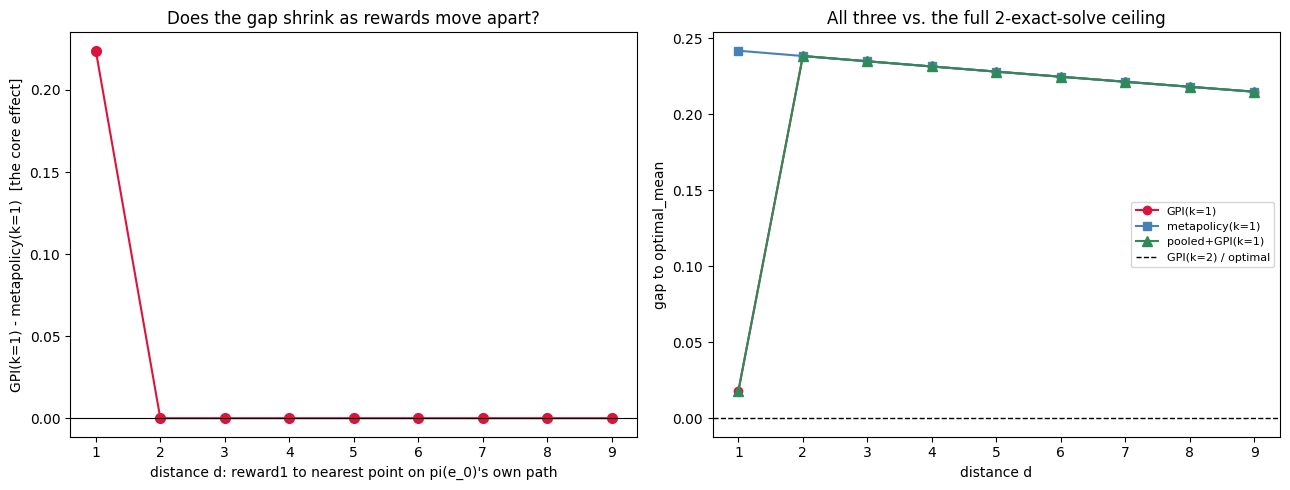

  d   GPI(k=1)-meta(k=1)    pooled(k=1) gap    GPI(k=1) gap  pool size
  1               0.2239             0.0179          0.0179         19
  2               0.0000             0.2384          0.2384         19
  3               0.0000             0.2349          0.2349         19
  4               0.0000             0.2315          0.2315         19
  5               0.0000             0.2281          0.2281         19
  6               0.0000             0.2247          0.2247         19
  7               0.0000             0.2214          0.2214         19
  8               0.0000             0.2181          0.2181         19
  9               0.0000             0.2149          0.2149         19


In [4]:
ds = [r["d"] for r in rows]
gap_gpi1 = [r["optimal"] - r["gpi1"] for r in rows]
gap_meta1 = [r["optimal"] - r["meta1"] for r in rows]
gap_pooled1 = [r["optimal"] - r["pooled1"] for r in rows]
gpi_minus_meta = [r["gpi1"] - r["meta1"] for r in rows]  # the core dose-response signal

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(ds, gpi_minus_meta, marker="o", ms=7, color="crimson")
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_xlabel("distance d: reward1 to nearest point on pi(e_0)'s own path")
axes[0].set_ylabel("GPI(k=1) - metapolicy(k=1)  [the core effect]")
axes[0].set_title("Does the gap shrink as rewards move apart?")

axes[1].plot(ds, gap_gpi1, marker="o", ms=6, color="crimson", label="GPI(k=1)")
axes[1].plot(ds, gap_meta1, marker="s", ms=6, color="steelblue", label="metapolicy(k=1)")
axes[1].plot(ds, gap_pooled1, marker="^", ms=7, color="seagreen", label="pooled+GPI(k=1)")
axes[1].axhline(0, color="black", ls="--", lw=1, label="GPI(k=2) / optimal")
axes[1].set_xlabel("distance d")
axes[1].set_ylabel("gap to optimal_mean")
axes[1].set_title("All three vs. the full 2-exact-solve ceiling")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print(f"{'d':>3} {'GPI(k=1)-meta(k=1)':>20} {'pooled(k=1) gap':>18} {'GPI(k=1) gap':>15} {'pool size':>10}")
for r in rows:
    print(f"{r['d']:>3} {r['gpi1']-r['meta1']:>20.4f} {r['optimal']-r['pooled1']:>18.4f} "
          f"{r['optimal']-r['gpi1']:>15.4f} {r['pool_size']:>10}")